In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
K_NEIGHBORS = 5

Load the Iris dataset

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
class_names = iris.target_names

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", list(X.columns))
print("Class names:", list(class_names))

Feature matrix shape: (150, 4)
Target shape: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [3]:
display(iris.frame.head())
display(iris.frame.describe().round(2))
print("Missing values by column:")
display(iris.frame.isna().sum())
print("Records per class:")
display(iris.frame["target"].value_counts().sort_index().rename(index=dict(enumerate(class_names))))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


Missing values by column:


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0


Records per class:


,count
target,
setosa,50
versicolor,50
virginica,50


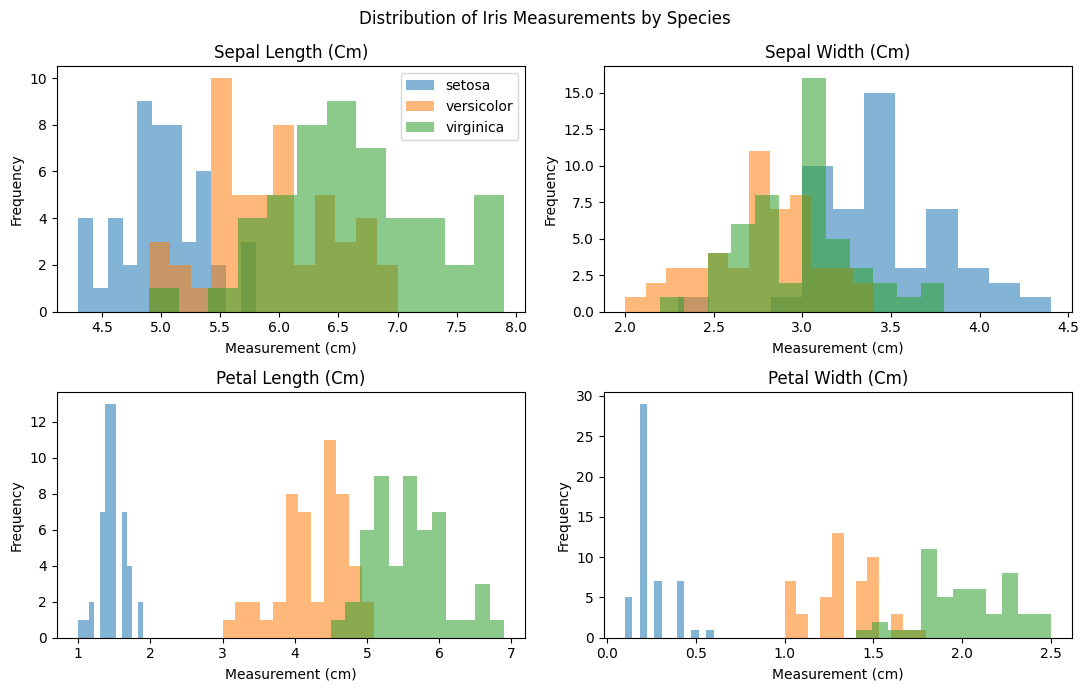

In [4]:
# Visualize the distribution of the four measurements by species.
plot_data = iris.frame.copy()
plot_data["species"] = plot_data["target"].map(dict(enumerate(class_names)))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature in zip(axes.ravel(), X.columns):
    for species in class_names:
        values = plot_data.loc[plot_data["species"] == species, feature]
        ax.hist(values, alpha=0.55, bins=12, label=species)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Measurement (cm)")
    ax.set_ylabel("Frequency")
axes[0, 0].legend()
plt.suptitle("Distribution of Iris Measurements by Species")
plt.tight_layout()
plt.show()

Split the data into training and testing sets

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nTraining class counts:")
print(pd.Series(y_train).map(dict(enumerate(class_names))).value_counts())
print("\nTesting class counts:")
print(pd.Series(y_test).map(dict(enumerate(class_names))).value_counts())

Training records: 120
Testing records: 30

Training class counts:
target
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing class counts:
target
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [6]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=K_NEIGHBORS))
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


Predict the test data

In [7]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Actual species": [class_names[i] for i in y_test],
    "Predicted species": [class_names[i] for i in y_pred]
})
display(results.head(10))

,Actual species,Predicted species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Evaluate model performance


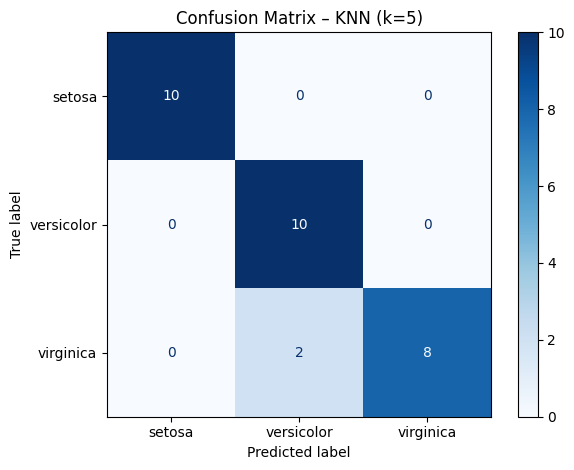

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – KNN (k=5)")
plt.tight_layout()
plt.show()

Cross-validation check

In [10]:
# Five-fold stratified cross-validation on the full dataset.
# Each fold is held out once; the pipeline scales within each fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")

print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

Fold accuracies: [1.     0.9667 0.9333 1.     0.9667]
Mean CV accuracy: 0.9733
Standard deviation: 0.0249


Predict a new flower

In [11]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)
predicted_class = model.predict(new_flower)[0]
print("Input measurements:")
display(new_flower)
print("Predicted species:", class_names[predicted_class])

Input measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted species: setosa
